# Risk and attribution

This notebook describes the recorded base-case books under the design in `configs/attribution.yaml`. It reruns no backtest and chooses no book. The primary window is the evaluation window, 2014-01-02 to 2021-12-08, and gross P&L is the primary series. The published factors are gross of their own trading costs, so net regressions are not like for like.

Results are read from `reports/attribution/`, and the summary is in `reports/attribution/SUMMARY.md`.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

OUT = Path("../reports/attribution")
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)
read = lambda name: pd.read_csv(OUT / f"{name}.csv")

GROSS, NET = "#2a78d6", "#eb6834"
BOOK_COLORS = {"lightgbm_h5_optimised": "#2a78d6", "lightgbm_h5_neutral_volscaled": "#eb6834",
               "B0_h5_optimised": "#1baf7a", "B0_h5_neutral_volscaled": "#eda100"}
BOOKS = list(BOOK_COLORS)
SIGNAL = {"lightgbm_h5": "lightgbm_h5_rank", "B0_h5": "B0_reversal_h5"}
TERMS = ["alpha", "mkt_rf", "smb", "hml", "rmw", "cma", "mom", "st_rev", "bab"]
LARGEST = "ff5_mom_strev_bab"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
meta = json.loads((OUT / "run_metadata.json").read_text())
{k: meta[k] for k in ("code_commit", "code_dirty", "last_factor_date", "holdout_start")}

{'code_commit': '02e044441afda64acc79b567fcd5fde8564513e5',
 'code_dirty': False,
 'last_factor_date': '2021-12-31',
 'holdout_start': '2022-01-01'}

## Checks

Every pre-registered check passed. The net regression on the universe return reproduces `reports/portfolio/exposures.csv` to 4e-15, and Mkt-RF lines up with the universe return at lag 0 (correlation 0.98, against -0.11 at the larger of lags ±1).

In [2]:
checks = read("checks")
display(checks.groupby("check").agg(rows=("passed", "size"), all_passed=("passed", "all"), largest_value=("value", "max")))

,rows,all_passed,largest_value
check,,,
coverage,1,True,0.000000e+00
date_alignment,1,True,9.783489e-01
decomposition,16,True,2.981556e-19
reproduce_exposures,8,True,3.996803e-15


## The confirmatory test

The pre-registered rule returns `reversal_explained`: the reversal beta is positive with t 10.4, and alpha t is 1.89, below the threshold of 2.

That label overstates the result. In the mean decomposition, the reversal factor accounts for 110 bp a year out of 592 bp, and alpha accounts for 355 bp. Alpha t is also just under the threshold.

In [3]:
display(read("primary_test").T)

,0
book,lightgbm_h5_neutral_volscaled
series,gross_pnl
window,evaluation
model,ff5_mom_strev_bab
n_days,1999
nw_lag,7
mean_return_ann,0.05923
alpha_ann,0.035457
alpha_t,1.886365
reversal_beta,0.166317


## Where the gross return comes from

The bars add up to each book's mean gross return. Scales are shared, so the headline book's small bars are a real difference. `st_rev` is the largest factor contribution in every book but the headline, where nothing stands out.

term,alpha,mkt_rf,smb,hml,rmw,cma,mom,st_rev,bab
book,,,,,,,,,
lightgbm_h5_optimised,0.3,0.5,0.1,5.1,1.4,-2.0,6.4,3.2,-0.2
lightgbm_h5_neutral_volscaled,1.9,3.7,-1.8,4.4,3.8,-3.6,15.8,10.4,0.9
B0_h5_optimised,0.5,-1.9,1.3,1.8,0.7,0.5,-9.8,9.3,-0.5
B0_h5_neutral_volscaled,0.6,1.3,0.4,1.8,-0.0,-1.0,-1.0,20.3,1.1


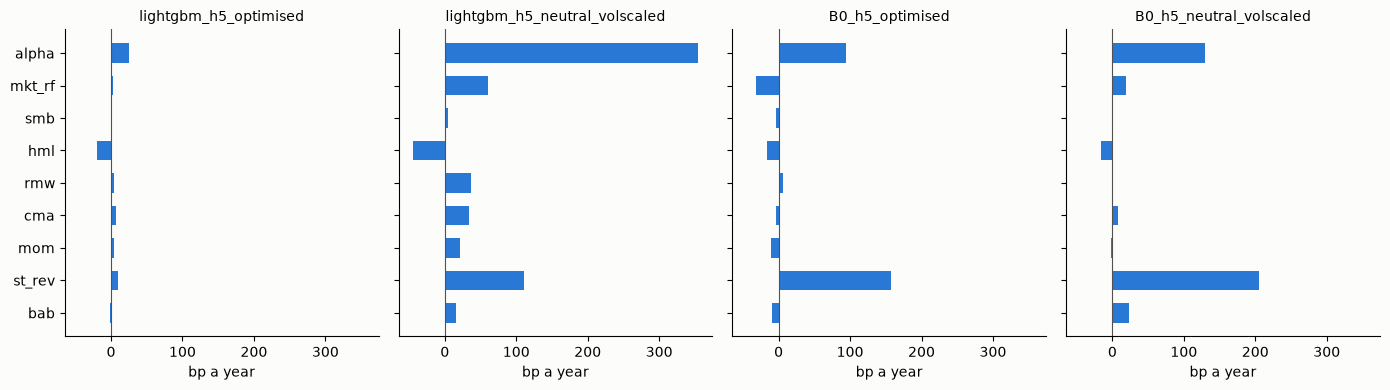

In [4]:
load = read("factor_loadings").query("series == 'gross_pnl' and window == 'evaluation' and model == @LARGEST")
fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharex=True, sharey=True)
for ax, book in zip(axes, BOOKS):
    s = load[load["book"] == book].set_index("term").loc[TERMS, "contribution_bp_per_year"]
    ax.barh(range(len(TERMS)), s, color=GROSS, height=0.6)
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_yticks(range(len(TERMS)), TERMS)
    ax.set_title(book, fontsize=10)
    ax.set_xlabel("bp a year")
axes[0].invert_yaxis()
fig.tight_layout()
fig.savefig(FIG / "gross_return_contributions.png", dpi=150)
display(load.pivot(index="book", columns="term", values="t").loc[BOOKS, TERMS].round(1))

## Alpha as the models grow

Alpha t for the LightGBM `neutral_volscaled` book moves between 1.57 and 2.06 across the nested models, so it sits on the threshold rather than clearly on one side. R² jumps from 0.13 to 0.40 when momentum is added, so momentum is the book's largest source of risk. It earns little (21 bp a year), because the momentum factor's mean was small in this window.

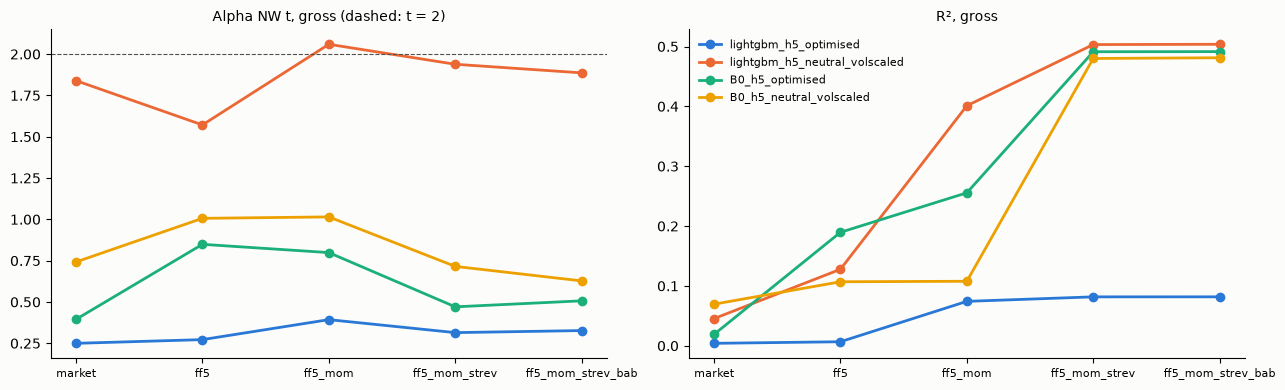

In [5]:
models = read("factor_models").query("series == 'gross_pnl' and window == 'evaluation'")
order = ["market", "ff5", "ff5_mom", "ff5_mom_strev", LARGEST]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for book in BOOKS:
    s = models[models["book"] == book].set_index("model").loc[order]
    for ax, col in zip(axes, ["alpha_t", "r2"]):
        ax.plot(order, s[col], marker="o", lw=2, ms=6, color=BOOK_COLORS[book], label=book)
axes[0].axhline(2, color="#52514e", lw=0.8, ls="--")
axes[0].set_title("Alpha NW t, gross (dashed: t = 2)", fontsize=10)
axes[1].set_title("R², gross", fontsize=10)
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.tick_params(axis="x", labelsize=8)
fig.tight_layout()
fig.savefig(FIG / "alpha_by_nested_model.png", dpi=150)

## The project's own reversal book

The published factor is a one-month, all-cap sort. Adding the B0 `neutral_volscaled` gross return makes the `st_rev` loading vanish (t 0.08), and the B0 book takes it over (beta 0.53, t 14.2, 195 bp a year). Alpha falls to 285 bp (t 1.65). The reversal in this book is a five-day reversal inside the S&P 500, more than the published one-month factor.

In [6]:
span = read("own_reversal_spanning")
display(span[["term", "coef", "t", "contribution_bp_per_year"]].round(3))
display(span[["alpha_ann", "alpha_t", "r2", "mean_return_ann"]].drop_duplicates().round(3))

,term,coef,t,contribution_bp_per_year
0,alpha,0.000,1.646,285.166
1,mkt_rf,0.035,3.202,50.990
2,smb,-0.039,-2.379,5.444
3,hml,0.078,4.227,-36.229
4,rmw,0.115,4.716,36.029
5,cma,-0.149,-4.152,30.166
6,mom,0.291,17.888,21.713
7,st_rev,0.001,0.084,0.906
8,bab,0.003,0.148,2.793
9,own_reversal_book,0.534,14.209,195.320


,alpha_ann,alpha_t,r2,mean_return_ann
0,0.029,1.646,0.643,0.059


## Net of costs

Net alpha is not like for like, because the factors are gross of their own costs. It is still reported: the two `neutral_volscaled` books have significantly negative net alpha, and the two `optimised` books are indistinguishable from zero.

In [7]:
net = read("factor_models").query("series == 'net_pnl' and model == @LARGEST")
display(net[["book", "window", "mean_return_ann", "alpha_ann", "alpha_t", "r2"]].round(3))

,book,window,mean_return_ann,alpha_ann,alpha_t,r2
9,lightgbm_h5_optimised,evaluation,-0.000,-0.001,-0.087,0.082
19,lightgbm_h5_optimised,tuning (in-sample for the lambdas),0.010,0.006,0.557,0.077
29,lightgbm_h5_neutral_volscaled,evaluation,-0.019,-0.043,-2.315,0.504
39,lightgbm_h5_neutral_volscaled,tuning (in-sample for the lambdas),-0.062,-0.078,-4.020,0.366
49,B0_h5_optimised,evaluation,-0.002,-0.010,-0.560,0.492
59,B0_h5_optimised,tuning (in-sample for the lambdas),0.043,0.016,0.577,0.456
69,B0_h5_neutral_volscaled,evaluation,-0.082,-0.105,-5.150,0.480
79,B0_h5_neutral_volscaled,tuning (in-sample for the lambdas),-0.119,-0.142,-7.083,0.342


## Risk

Scales are shared. The gross `neutral_volscaled` drawdowns are moderate, but costs turn them into long declines. B0 `neutral_volscaled` net is under water for almost the whole window, at -70.5% of capital. March 2020 is B0's worst stretch gross, and it recovered within weeks.

,book,series,return_ann,vol_ann,sharpe,skew_daily,excess_kurtosis_daily,skew_h_day,worst_day,worst_day_date,worst_month,worst_month_period
0,lightgbm_h5_optimised,gross_pnl,0.003,0.024,0.136,-0.001,2.164,-0.393,-0.008,2020-06-08,-0.019,2015-12
1,lightgbm_h5_optimised,net_pnl,-0.000,0.024,-0.001,-0.003,2.165,-0.402,-0.008,2020-06-08,-0.019,2015-12
4,lightgbm_h5_neutral_volscaled,gross_pnl,0.059,0.074,0.797,0.032,6.683,0.876,-0.032,2020-11-09,-0.057,2015-04
5,lightgbm_h5_neutral_volscaled,net_pnl,-0.019,0.074,-0.261,0.017,6.648,0.842,-0.033,2020-11-09,-0.062,2015-04
8,B0_h5_optimised,gross_pnl,0.018,0.069,0.263,1.764,23.231,2.030,-0.036,2020-03-17,-0.040,2019-08
9,B0_h5_optimised,net_pnl,-0.002,0.069,-0.026,1.711,23.010,1.930,-0.037,2020-03-17,-0.043,2019-08
12,B0_h5_neutral_volscaled,gross_pnl,0.037,0.072,0.507,0.501,15.749,1.131,-0.035,2020-03-09,-0.049,2020-03
13,B0_h5_neutral_volscaled,net_pnl,-0.082,0.072,-1.135,0.468,15.627,1.067,-0.036,2020-03-09,-0.060,2020-03


,book,series,depth,peak,trough,recovery,days_under_water
0,lightgbm_h5_optimised,gross_pnl,-0.052,2019-10-31,2021-01-27,NaN,530
3,lightgbm_h5_optimised,net_pnl,-0.055,2019-10-31,2021-01-27,NaN,530
12,lightgbm_h5_neutral_volscaled,gross_pnl,-0.109,2020-11-06,2021-10-12,NaN,273
15,lightgbm_h5_neutral_volscaled,net_pnl,-0.256,2016-06-27,2021-10-12,NaN,1373
24,B0_h5_optimised,gross_pnl,-0.193,2015-05-07,2020-03-18,2020-04-09,1239
27,B0_h5_optimised,net_pnl,-0.286,2015-05-07,2020-03-18,NaN,1660
36,B0_h5_neutral_volscaled,gross_pnl,-0.240,2019-08-01,2020-03-18,2020-04-20,179
39,B0_h5_neutral_volscaled,net_pnl,-0.705,2014-01-07,2020-03-18,NaN,1995


,book,horizon_days,var,es,var_in_daily_vols,es_in_daily_vols
2,lightgbm_h5_optimised,1,0.0038,0.0049,2.5317,3.2843
3,lightgbm_h5_optimised,5,0.0082,0.0105,5.4579,6.9546
18,lightgbm_h5_neutral_volscaled,1,0.0140,0.0180,2.9971,3.8400
19,lightgbm_h5_neutral_volscaled,5,0.0284,0.0383,6.0795,8.1764
34,B0_h5_optimised,1,0.0107,0.0160,2.4562,3.6708
35,B0_h5_optimised,5,0.0222,0.0392,5.1021,9.0273
50,B0_h5_neutral_volscaled,1,0.0109,0.0180,2.3890,3.9652
51,B0_h5_neutral_volscaled,5,0.0296,0.0518,6.5112,11.4051


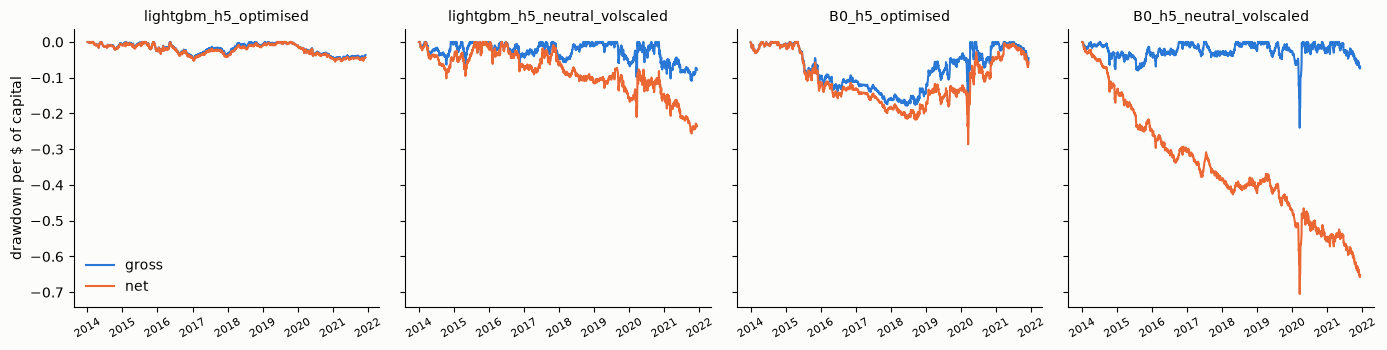

In [8]:
rows = {}
root = Path("../data/processed/portfolio")
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)
for ax, book in zip(axes, BOOKS):
    signal = next(v for k, v in SIGNAL.items() if book.startswith(k))
    construction = book.split("_h5_")[1]
    d = pd.read_parquet(root / signal / "portfolio_daily_returns.parquet",
                        filters=[("tranche", "==", "total"), ("scenario", "==", "base"), ("construction", "==", construction)])
    d["date"] = pd.to_datetime(d["date"])
    d = d[d["date"] >= "2014-01-02"].set_index("date").sort_index()
    for col, color, name in (("gross_pnl", GROSS, "gross"), ("net_pnl", NET, "net")):
        equity = d[col].cumsum()
        ax.plot(equity - equity.cummax().clip(lower=0), color=color, lw=1.5, label=name)
    ax.set_title(book, fontsize=10)
    ax.tick_params(axis="x", labelsize=8, rotation=30)
axes[0].set_ylabel("drawdown per $ of capital")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "drawdowns.png", dpi=150)
risk = read("risk_statistics").query("window == 'evaluation'")
display(risk[["book", "series", "return_ann", "vol_ann", "sharpe", "skew_daily", "excess_kurtosis_daily", "skew_h_day",
              "worst_day", "worst_day_date", "worst_month", "worst_month_period"]].round(3))
display(read("drawdowns").query("window == 'evaluation' and `rank` == 1")[["book", "series", "depth", "peak", "trough", "recovery", "days_under_water"]].round(3))
display(read("var_es").query("window == 'evaluation' and series == 'gross_pnl' and confidence == 0.99")[
    ["book", "horizon_days", "var", "es", "var_in_daily_vols", "es_in_daily_vols"]].round(4))

## Why realised beta differs from ex-ante

Every realised-beta interval excludes the mean ex-ante beta, so the gap isn't estimation noise. Changing the market proxy doesn't close it, and neither does a 63-day beta: for the LightGBM `neutral_volscaled` book, that exposure has the opposite sign to the realised beta. There is no significant up-versus-down asymmetry.

The factor controls move it most. For the two B0 books, realised beta falls to about zero once `st_rev` enters the model (0.084 to 0.014 and 0.031 to -0.022), so much of it is the reversal factor's own market exposure. The LightGBM `neutral_volscaled` book keeps 0.042.

model,market,ff5,ff5_mom,ff5_mom_strev,ff5_mom_strev_bab
book,,,,,
lightgbm_h5_optimised,0.009,0.007,0.005,0.002,0.002
lightgbm_h5_neutral_volscaled,0.090,0.093,0.080,0.043,0.042
B0_h5_optimised,0.054,0.025,0.031,-0.022,-0.022
B0_h5_neutral_volscaled,0.108,0.084,0.084,0.014,0.013


,book,market_proxy,beta_down,beta_up,up_minus_down,up_minus_down_t
0,lightgbm_h5_optimised,equal_weighted,0.005,0.009,0.003,0.392
1,lightgbm_h5_optimised,value_weighted,0.005,0.013,0.008,0.928
8,lightgbm_h5_neutral_volscaled,equal_weighted,0.064,0.054,-0.009,-0.148
9,lightgbm_h5_neutral_volscaled,value_weighted,0.079,0.103,0.025,0.453
16,B0_h5_optimised,equal_weighted,0.038,0.170,0.131,1.708
17,B0_h5_optimised,value_weighted,0.027,0.086,0.060,0.755
24,B0_h5_neutral_volscaled,equal_weighted,0.120,0.129,0.010,0.106
25,B0_h5_neutral_volscaled,value_weighted,0.117,0.098,-0.019,-0.190


,book,market_proxy,exposure,b0,b0_t_vs_0,b1,b1_t_vs_1
0,lightgbm_h5_optimised,equal_weighted,beta_ex_ante,0.01,1.24,1.25,0.36
1,lightgbm_h5_optimised,equal_weighted,exposure_short_beta,0.01,1.93,0.56,-2.25
2,lightgbm_h5_optimised,value_weighted,beta_ex_ante,0.01,1.86,0.99,-0.02
3,lightgbm_h5_optimised,value_weighted,exposure_short_beta,0.01,2.49,0.45,-2.83
16,lightgbm_h5_neutral_volscaled,equal_weighted,beta_ex_ante,0.02,0.90,3.25,2.63
17,lightgbm_h5_neutral_volscaled,equal_weighted,exposure_short_beta,0.06,2.40,0.91,-0.51
18,lightgbm_h5_neutral_volscaled,value_weighted,beta_ex_ante,0.07,3.61,1.86,1.17
19,lightgbm_h5_neutral_volscaled,value_weighted,exposure_short_beta,0.09,4.85,0.56,-2.67
32,B0_h5_optimised,equal_weighted,beta_ex_ante,0.08,4.43,0.99,-0.02
33,B0_h5_optimised,equal_weighted,exposure_short_beta,0.10,4.87,0.12,-2.69


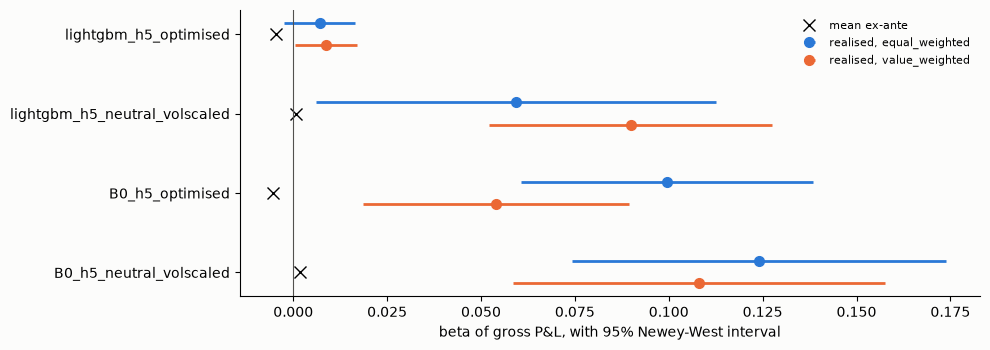

In [9]:
beta = read("beta_comparison").query("window == 'evaluation' and series == 'gross_pnl'")
fig, ax = plt.subplots(figsize=(10, 3.6))
for offset, (proxy, color) in zip((-0.14, 0.14), (("equal_weighted", GROSS), ("value_weighted", NET))):
    s = beta[beta["market_proxy"] == proxy].set_index("book").loc[BOOKS]
    y = np.arange(len(BOOKS)) + offset
    ax.errorbar(s["realised_beta"], y, xerr=[s["realised_beta"] - s["ci95_low"], s["ci95_high"] - s["realised_beta"]],
                fmt="o", ms=7, lw=2, color=color, label=f"realised, {proxy}")
s = beta[beta["market_proxy"] == "equal_weighted"].set_index("book").loc[BOOKS]
ax.plot(s["mean_beta_ex_ante"], range(len(BOOKS)), "kx", ms=9, label="mean ex-ante")
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks(range(len(BOOKS)), BOOKS)
ax.invert_yaxis()
ax.set_xlabel("beta of gross P&L, with 95% Newey-West interval")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "realised_vs_ex_ante_beta.png", dpi=150)
display(read("beta_factor_controls").query("window == 'evaluation' and series == 'gross_pnl'").pivot(
    index="book", columns="model", values="coef").loc[BOOKS, order].round(3))
display(read("beta_up_down").query("window == 'evaluation' and series == 'gross_pnl'")[
    ["book", "market_proxy", "beta_down", "beta_up", "up_minus_down", "up_minus_down_t"]].round(3))
display(read("beta_conditional").query("window == 'evaluation' and series == 'gross_pnl'")[
    ["book", "market_proxy", "exposure", "b0", "b0_t_vs_0", "b1", "b1_t_vs_1"]].round(2))

## Conclusion

The 0.80 gross Sharpe is not simply the published reversal factor. That factor loads strongly but explains under a fifth of the mean return. The project's own five-day reversal book explains about a third, and 285 bp a year of alpha remains that can't be told apart from zero. After costs, nothing remains.